# EECE568 - Assignment 3

### Mount on Google Drive (preferred)


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

In [ ]:
%cd gdrive/My Drive/path_to_assignment_folder/

In [ ]:
!pip install umap-learn

### or Run Locally

Create an environment using conda and install the dependencies using poetry.

Run the following commands in your terminal.

- conda create --name ece568 python=3.9 pip
- conda activate ece568
- pip install poetry

Go to the folder containing the pyproject.toml, and run the following command:
- poetry install --no-root
- poetry shell

### Imports

In [ ]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from IPython import display

# import standard PyTorch modules
import torch
import torch.nn as nn
import torch.nn.functional as F

import umap

# import torchvision module to handle image manipulation
import torchvision
import torchvision.transforms as transforms
print("Running on torch.__version__ = ", torch.__version__)

torch.backends.cudnn.deterministic = True

# utils
from tqdm.notebook import tqdm
from collections import Counter

Running on torch.__version__ =  2.4.1+cu121


### Helper Functions

In [ ]:
# a function to move tensors from the CPU to the GPU and vice versa
def dict_to_device(orig, device):
    new = {}
    for k,v in orig.items():
        new[k] = v.to(device)
    return new

# a function to plot a batch of images together
def plot_images(img, ax):
    img = torchvision.utils.make_grid(img)
    npimg = img.numpy()
    ax.imshow(np.transpose(npimg, (1, 2, 0)))

# a function to make a tuples
def pair(t):
    return t if isinstance(t, tuple) else (t, t)

## Q1 (10 pts)

### Load and Tokenize Data

In [ ]:
data = pd.read_csv('./imdb_processed.csv')
data.head()

In [ ]:
# obtain list of words
words = ' '.join(data.processed.values).split()

# check our list
words[30:40]

In [ ]:
# build vocabulary
counter = Counter(words)
vocab = sorted(counter, key=counter.get, reverse=True)
token2word = dict(enumerate(vocab, 1))
token2word[0] = '<PAD>'
word2token = {word: id for id, word in token2word.items()}

print("vocab size:", len(word2token))

In [ ]:
# tokenize reviews
reviews = data.processed.values
reviews_tokenized = [[word2token[word] for word in review.split()] for review in tqdm(reviews)]

# padding sequences
def pad_features(reviews, pad_id, seq_length):
    features = np.full((len(reviews), seq_length), pad_id, dtype=int)
    for i, row in enumerate(reviews):
        features[i, :len(row)] = np.array(row)[:seq_length]

    return features

SEQ_LENGTH = 100
features = pad_features(reviews_tokenized, pad_id=word2token['<PAD>'], seq_length=SEQ_LENGTH)

print('number of reviews:', len(reviews_tokenized))
print('seq_length:', len(features[0]))

# print first-5 words of first 3 reviews
print('\n first-five words of the first-three reviews:')
print('===============')
features[:3, :5]

### Dataloader

In [ ]:
# we use 70%, 15%, 15% for train, validation, and test sets
train_size = .7
val_size = .5
labels = data.label.to_numpy()

# make train set
split_id = int(len(features) * train_size)
train_x, remain_x = features[:split_id], features[split_id:]
train_y, remain_y = labels[:split_id], labels[split_id:]

# make val and test set
split_val_id = int(len(remain_x) * val_size)
val_x, test_x = remain_x[:split_val_id], remain_x[split_val_id:]
val_y, test_y = remain_y[:split_val_id], remain_y[split_val_id:]

# print out the shape
print('Train set: {}'.format(train_x.shape))
print('Validation set: {}'.format(val_x.shape))
print('Test set: {}'.format(test_x.shape))

In [ ]:
class MyDataset(torch.utils.data.Dataset):
    def __init__(self, reviews, labels):
        self.data = torch.utils.data.TensorDataset(torch.from_numpy(reviews), torch.from_numpy(labels).float())

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        review = self.data[index][0]
        label = self.data[index][1]

        return {'review': review, 'label': label}


train_set = MyDataset(train_x, train_y)
val_set = MyDataset(val_x, val_y)
test_set = MyDataset(test_x, test_y)

train_loader = torch.utils.data.DataLoader(train_set, shuffle=True, batch_size=256)
val_loader = torch.utils.data.DataLoader(val_set, shuffle=False, batch_size=256)
test_loader = torch.utils.data.DataLoader(test_set, shuffle=False, batch_size=256)

### ToDo: Network (5 pts)

Implement a **Transformer** classifier that takes a series of words (a review) as input and returns the label of the review indicating whether it is positive (1) or negative (0).

Your network should take a python dictionary as input and extract the input sentences from it. Your network should return a python dictionaly containing the
predicted label ('label') and the self-attention weights ('attention') from the last encoder layer in your transformer.

In [ ]:
# ToDo: Implement your network
class Transformer(nn.Module):
    def __init__(self):
        super(Transformer, self).__init__()

        # ToDo: code here

        # - start with an embedding layer to convert word tokens into vector embeddings
        # - add positional encodings to word emebeddings
        # - using dropout might be helpful
        # - use a transformer encoder to calculate the attention weights
        # - apply an mlp head on top of the transformer to predict the label


    def forward(self, input_dict):
        x = input_dict['review']

        # ToDo: code here

        return {'label': None, 'attention': None}

network = Transformer().to('cuda')

In [ ]:
total_params = sum(p.numel() for p in network.parameters())
print(f'The model has {total_params:,} parameters.')

### Training

In [ ]:
# feel free to implement your own loss function or use the suggested one here.

def my_loss_function(predicted_index, target_index):
  loss = nn.CrossEntropyLoss()(predicted_index, target_index)

  return loss

In [ ]:
# training loop
%matplotlib inline

# prepare plotting
fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,2)

optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

num_epochs = 10
train_losses = []
val_losses = []

for e in range(num_epochs):
    train_iter = iter(train_loader)
    network.train()
    for i in range(len(train_loader)):
        batch_cpu = next(train_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss and backward the gradient
        loss = my_loss_function(pred['label'], batch_gpu['label'].long())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

        if i%100==0:
            axes[0].cla()

            # plot the training error on a log plot
            axes[0].plot(train_losses, label='loss')
            axes[0].set_yscale('log')
            axes[0].set_title('Training loss')
            axes[0].set_xlabel('number of gradient iterations')
            axes[0].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Training epoch {}, iteration {} of {} ({} %), loss={:0.5f}".format(e, i, len(train_loader), 100*i//len(train_loader), train_losses[-1]))

    val_iter = iter(val_loader)
    network.eval()
    for i in range(len(val_loader)):
        batch_cpu = next(val_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss
        with torch.no_grad():
            loss = my_loss_function(pred['label'], batch_gpu['label'].long())
            val_losses.append(loss.item())

        if i%10==0:
            axes[1].cla()

            # plot the validation error on a log plot
            axes[1].plot(val_losses, label='loss')
            axes[1].set_yscale('log')
            axes[1].set_title('Validation loss')
            axes[1].set_xlabel('number of gradient iterations')
            axes[1].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Validation epoch {}, iteration {} of {} ({} %), loss={:0.5f}".format(e, i, len(val_loader), 100*i//len(val_loader), val_losses[-1]))
plt.close('all')

### ToDo: Evaluation


#### Prediction Accuracy (1 pt)
The 'get_accuracy' function assumes that the network returns class probabilities as output. If your network returns class indices, you might need to change this evaluation function as well.

In [ ]:
def get_accuracy(network, data_loader):
    network.eval()
    iterator = iter(data_loader)
    correct = 0
    total = 0
    for i in range(len(iterator)):
        batch_cpu = next(iterator)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)['label'].argmax(dim=1, keepdim=True)
        correct += pred.eq(batch_gpu['label'].view_as(pred)).sum().item()
        total += pred.shape[0]

    return correct / total

In [ ]:
# ToDo: report accuracy on train, validation, and test sets
print('train acc:', get_accuracy(network, train_loader))
print('validation acc:', get_accuracy(network, val_loader))
print('test acc:', get_accuracy(network, test_loader))

#### Attention Heatmap (2 pts)
Here, we want to visualize the self-attention weights between the class token and tokens in a sentence using a heatmap. Visualize the attention between the tokens of a random review from the test-set. Use the attention from the last layer of your transformer. If you are using a multi-head sturcture, take the average between the heads of the last layer.

The sum of attentions over all tokens in a sentence should be very close to 1.0.


In [ ]:
# a function to plot the attention weights' heatmap
def plot_attention_heatmap(attention, tokens):
    '''
    attention:  a numpy ndarray or tensor of shape [sequence_length]
                contains the attention between cls token and each token in the sentence

    tokens:     a numpy ndarray or tensor of shape [sequence_length]
                contains token in the sentence
    '''

    print(f'Sum of attentions over all tokens in a sentence: {attention.sum().item():.3f}')

    tokens = tokens.detach().cpu().numpy() if torch.is_tensor(tokens) else tokens
    attention = attention.detach().cpu().numpy() if torch.is_tensor(attention) else attention

    plot_dim = int(np.sqrt(len(tokens)))
    attention = attention.reshape(plot_dim, plot_dim)
    tokens = tokens.reshape(plot_dim, plot_dim)

    # Plot the attention weights for the first example in the batch and the first head in the last layer
    fig, ax = plt.subplots(figsize=(len(tokens) + 2, len(tokens) + 2))
    im = ax.imshow(attention, cmap='magma', interpolation='nearest')

    # Add the token names to the x-axis
    ax.set_xticks(np.arange(tokens.shape[1]))
    ax.tick_params(axis='x', which='both', bottom=False, top=True, labelbottom=False, labeltop=True)

    # Add the token names to the y-axis
    ax.set_yticks(np.arange(tokens.shape[0]))

    for i in range(tokens.shape[0]):
      for j in range(tokens.shape[1]):
        value = attention[i, j]
        text = ax.text(j, i, f"{token2word[tokens[i, j].item()]}", ha="center", va="center", color="black")

    # Add colorbar
    cbar = ax.figure.colorbar(im, ax=ax)
    plt.show()

Sum of attentions over all tokens in a sentence: 0.999


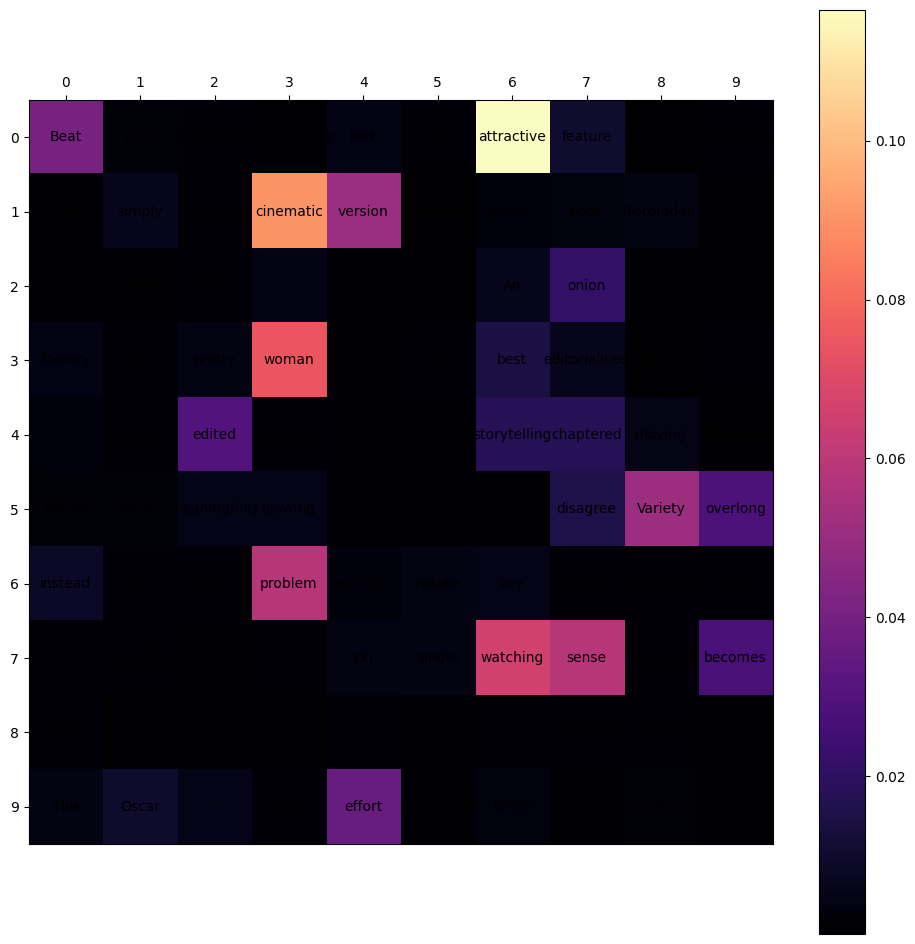

In [ ]:
# ToDo: plot the heatmap of the self-attention weights
test_iter = iter(test_loader)
network.eval()
for i in range(len(test_loader)):
    batch_cpu = next(test_iter)
    batch_gpu = dict_to_device(batch_cpu, 'cuda')
    pred = network(batch_gpu)

    # ToDo: code here
    # Hint: use 'plot_attention_heatmap' function above

    break

#### Word Embeddings (2 pts)
Here, we want to visualize the learned embeddings for our vocabulary words. To do that, we use u-map, which is a machine learning technique for visualizing high-dimensional data by mapping it to a low-dimensional space (usually 2D or 3D).

In [ ]:
def plot_umap(embeddings, n_words=100):
    '''
    embeddings: numpy ndarray of shape [vocabulary_size, word_embedding_dim]
    '''
    np.random.seed(42)
    offset=0

    # Dimensionality reduction using UMAP
    reducer = umap.UMAP(n_components=2, random_state=42)
    embeddings_2d = reducer.fit_transform(embeddings[offset:offset + n_words])

    # Plotting
    plt.figure(figsize=(16, 10))
    x_coords = embeddings_2d[:, 0]
    y_coords = embeddings_2d[:, 1]

    plt.scatter(x_coords, y_coords, marker='o', color='red')

    # Optionally, label a subset to avoid clutter
    for i, word in enumerate(words[offset:offset + n_words]):
        plt.annotate(word, (x_coords[i], y_coords[i]), fontsize=9)

    plt.xlabel('UMAP Dimension 1')
    plt.ylabel('UMAP Dimension 2')
    plt.title('Word Embeddings Visualization with UMAP')
    plt.grid(True)
    plt.show()

/usr/local/lib/python3.10/dist-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


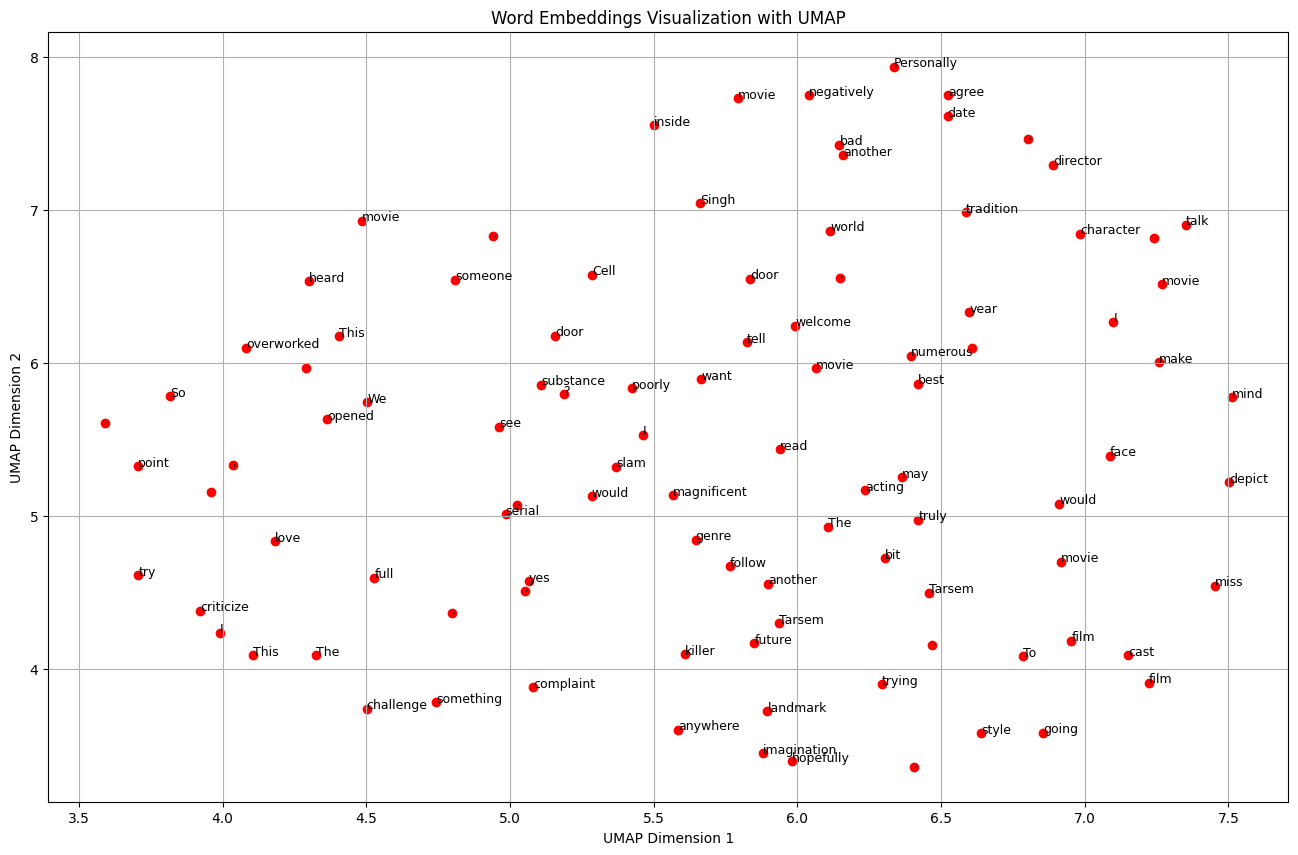

In [ ]:
# ToDo: plot the learned word-embeddings in 2D

# ToDo: code here
# Hint: use 'plot_umap' function above. simply give the word-embedding module of your network as input.

## Q2 (6 pts)

### Dataset and Dataloader

In [ ]:
# Use standard MNIST dataset
class MyDataset(torchvision.datasets.MNIST):
    def __init__(self, *args, debug=False, **kwargs):
        super().__init__(*args, **kwargs)
        self.debug = debug

    def __getitem__(self, idx):
        data = super().__getitem__(idx)
        img = data[0]
        digit = data[1]
        return {'image': img, 'digit': digit}

    def __len__(self):
        return super().__len__()

dataset = MyDataset(
    root = './',
    train = True,
    download = True,
    transform = transforms.Compose([
        transforms.ToTensor(),
    ]),
    debug=True,
)

test_set = MyDataset(
    root = './',
    train = False,
    download = True,
    transform = transforms.Compose([
        transforms.ToTensor(),
    ]),
    debug=True,
)

loader = torch.utils.data.DataLoader(dataset, batch_size=128, num_workers=0)

In [ ]:
# Define the dataloaders and split into train, validation, and test

size = len(dataset)
train_set, val_set = torch.utils.data.random_split(dataset, [int(size * 0.8), int(size * 0.2)])
train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=128, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=128, shuffle=False, num_workers=0)

print('train_set:', len(train_set))
print('val_set:', len(val_set))
print('test_set:', len(test_set))

### ToDo: Network (2 pts)

Implement a **Vision Transformer** that takes an image as input and classifies it into ten classes, digits 0 to 9.

Your network should take a python dictionary as input and extract the input image from it. Your network should return a python dictionaly containing the
predicted class ('digit') of the input image.

In [ ]:
# ToDo: Implement your network
class ViT(nn.Module):
    def __init__(self):
        super(ViT, self).__init__()

        # ToDo: code here

        # - start with a patch_embedding layer to divide image into patches and
        #   convert each patch into vector embeddings
        # - append a class token to image tokens
        # - add positional encodings
        # - using dropout might be helpful
        # - use a transformer encoder to calculate the attention weights
        # - apply an mlp head on the class token to predict the digit


    def forward(self, input_dict):
        x = input_dict['image']

        # ToDo: code here

        return {'digit': None}

network = ViT().to('cuda')

In [ ]:
total_params = sum(p.numel() for p in network.parameters())
print(f'The model has {total_params:,} parameters.')

### Training

In [ ]:
# training loop
%matplotlib inline

# prepare plotting
fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,3)

optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

num_epochs = 10
train_losses = []
val_losses = []

for e in range(num_epochs):
    train_iter = iter(train_loader)
    network.train()
    for i in range(len(train_loader)):
        batch_cpu = next(train_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss and backward the gradient
        loss = nn.CrossEntropyLoss()(pred['digit'], batch_gpu['digit'])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

        if i%100==0:
            axes[0].cla()
            axes[1].cla()

            # plot some sample image inputs
            plot_images(batch_cpu['image'][0:1], ax=axes[0])
            axes[0].legend()
            axes[0].set_title('sample input')

            # plot the training error on a log plot
            axes[1].plot(train_losses, label='loss')
            axes[1].set_yscale('log')
            axes[1].set_title('Training loss')
            axes[1].set_xlabel('number of gradient iterations')
            axes[1].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Training epoch {}, iteration {} of {} ({} %), loss={:0.4f}".format(e, i, len(train_loader), 100*i//len(train_loader), train_losses[-1]))

    val_iter = iter(val_loader)
    network.eval()
    for i in range(len(val_loader)):
        batch_cpu = next(val_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss
        with torch.no_grad():
            loss = nn.CrossEntropyLoss()(pred['digit'], batch_gpu['digit'])
            val_losses.append(loss.item())

        if i%10==0:
            axes[2].cla()

            # plot the validation error on a log plot
            axes[2].plot(val_losses, label='loss')
            axes[2].set_yscale('log')
            axes[2].set_title('Validation loss')
            axes[2].set_xlabel('number of gradient iterations')
            axes[2].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Validation epoch {}, iteration {} of {} ({} %), loss={:0.4f}".format(e, i, len(val_loader), 100*i//len(val_loader), val_losses[-1]))
plt.close('all')

### ToDo: Evaluation

#### Prediction Accuracy (1 pt)

The 'get_accuracy' function assumes that the network returns class probabilities as output. If your network returns class indices, you might need to change this evaluation function as well.

In [ ]:
def get_accuracy(network, data_loader):
    network.eval()
    iterator = iter(data_loader)
    correct = 0
    total = 0
    for i in range(len(iterator)):
        batch_cpu = next(iterator)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)['digit'].argmax(dim=1, keepdim=True)
        correct += pred.eq(batch_gpu['digit'].view_as(pred)).sum().item()
        total += pred.shape[0]

    return correct / total

In [ ]:
# ToDo: report accuracy on train, validation, and test sets
print('train acc:', get_accuracy(network, train_loader))
print('validation acc:', get_accuracy(network, val_loader))
print('test acc:', get_accuracy(network, test_loader))

#### Qualitative Results (1 pt)

For a few samples in the test set (6 samples in the code below), plot the input images and their predicted digits.

predicted labels: [4 0 2 6 9 0]


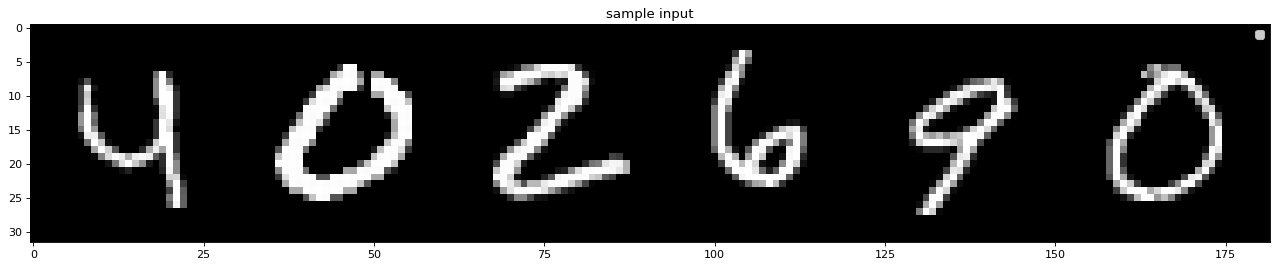

In [ ]:
# ToDo: plot the input images and output of your network for a few samples in the test set

fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,1)

test_iter = iter(test_loader)
network.eval()
for i in range(len(test_loader)):
    batch_cpu = next(test_iter)
    axes.cla()
    plot_images(batch_cpu['image'][0:6], ax=axes)
    axes.legend()
    axes.set_title('sample input')

    batch_gpu = dict_to_device(batch_cpu, 'cuda')
    pred = network(batch_gpu)

    # ToDo: code here. get the digits from the predicted probabilities.
    print("predicted digits:", None)

    break

#### Attention Heatmap (2 pt)

For a few samples in the test set, overlay the attention heatmaps on images, and plot the overlayed images.

By attention weights, we mean the self-attention weights between the cls token and each image patch.

Also print the sum of attention for each image which should be close to 1.

tensor(0.9843, device='cuda:0', grad_fn=<SumBackward0>)
tensor(0.9422, device='cuda:0', grad_fn=<SumBackward0>)
tensor(0.9948, device='cuda:0', grad_fn=<SumBackward0>)
tensor(0.9905, device='cuda:0', grad_fn=<SumBackward0>)
tensor(0.9967, device='cuda:0', grad_fn=<SumBackward0>)
tensor(0.9905, device='cuda:0', grad_fn=<SumBackward0>)


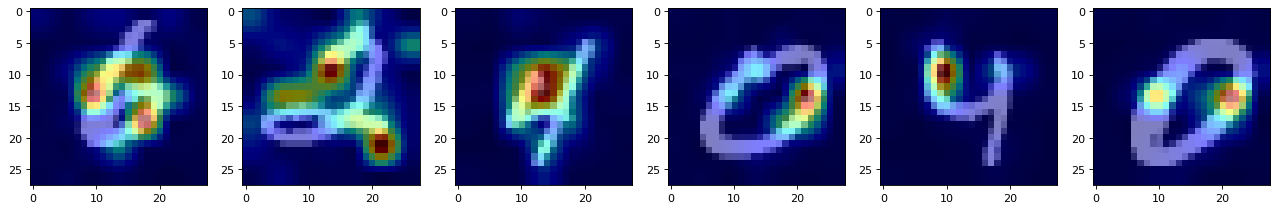

In [ ]:
# ToDo: Plot the attention weights

fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
n_subplots = 6
axes = fig.subplots(1, n_subplots)

test_iter = iter(test_loader)
network.eval()
for k in range(n_subplots):
    for i in range(len(test_loader)):
        batch_cpu = next(test_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')

        pred = network(batch_gpu)
        image = batch_cpu['image'][0]

        # ToDo: code here. Plot the attention weights overlayed on images.


        break
fig.show()

## Q3 (4 pts)

### Dataset and Dataloader

In [ ]:
# Use standard MNIST dataset
class MyDataset(torchvision.datasets.MNIST):
    def __init__(self, *args, debug=False, **kwargs):
        super().__init__(*args, **kwargs)
        self.debug = debug

    def __getitem__(self, idx):
        data = super().__getitem__(idx)
        img = data[0]
        digit = data[1]
        is_flipped = random.randint(0, 1)
        if is_flipped:
            img = torch.flip(img, [1])

        return {'image': img, 'digit': digit, 'is_flipped': is_flipped}

    def __len__(self):
        return super().__len__()

dataset = MyDataset(
    root = './',
    train = True,
    download = True,
    transform = transforms.Compose([
        transforms.ToTensor(),
    ]),
    debug=True,
)

test_set = MyDataset(
    root = './',
    train = False,
    download = True,
    transform = transforms.Compose([
        transforms.ToTensor(),
    ]),
    debug=True,
)

loader = torch.utils.data.DataLoader(dataset, batch_size=128, num_workers=0)

In [ ]:
# Define the dataloaders and split into train, validation, and test

size = len(dataset)
train_set, val_set = torch.utils.data.random_split(dataset, [int(size * 0.8), int(size * 0.2)])
train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=128, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=128, shuffle=False, num_workers=0)

print('train_set:', len(train_set))
print('val_set:', len(val_set))
print('test_set:', len(test_set))

### ToDo: Network (2 pts)

Implement a **Multi-Task Vision Transformer** that takes an image as input and classifies it into ten classes, digits 0 to 9. Also, it predicts whether the image is upside down (vertically flipped) or not.

Your network should take a dictionary as input and extract the input image from it. Your network should return a dictionaly with keys 'digit' and 'is_flipped', indicating the digit of the image and whether it is vertically flipped.

In [ ]:
# ToDo: Implement your network
class MultiViT(nn.Module):
    def __init__(self):
        super(MultiViT, self).__init__()

        # ToDo: code here

        # - start with a patch_embedding layer to divide image into patches and
        #   convert each patch into vector embeddings
        # - append a class token to image tokens for digit prediction
        # - append another class token for predicting if the image is flipped
        # - add positional encodings
        # - using dropout might be helpful
        # - use a transformer encoder to calculate the attention weights
        # - apply an mlp head on the first class token to predict the digit
        # - apply an mlp head on the second class token to predict the inversion


    def forward(self, input_dict):
        x = input_dict['image']

        # ToDo: code here

        return {'digit': None, 'is_flipped': None}

network = MultiViT().to('cuda')

In [ ]:
total_params = sum(p.numel() for p in network.parameters())
print(f'The model has {total_params:,} parameters.')

### Training

In [ ]:
# feel free to implement your own loss function or use the suggested one here.

def my_loss_function(predicted_index, target_index):
  loss = nn.CrossEntropyLoss()(predicted_index, target_index)

  return loss

In [ ]:
# training loop
%matplotlib inline

# prepare plotting
fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,4)

optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

num_epochs = 10
train_losses_digit = []
train_losses_flipped = []
val_losses = []

for e in range(num_epochs):
    train_iter = iter(train_loader)
    network.train()
    for i in range(len(train_loader)):
        batch_cpu = next(train_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss and backward the gradient
        loss_digit = my_loss_function(pred['digit'], batch_gpu['digit'])
        loss_flipped = my_loss_function(pred['is_flipped'], batch_gpu['is_flipped'])
        loss = loss_digit + loss_flipped
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses_digit.append(loss_digit.item())
        train_losses_flipped.append(loss_flipped.item())

        if i%100==0:
            axes[0].cla()
            axes[1].cla()
            axes[2].cla()

            # plot some sample image inputs
            plot_images(batch_cpu['image'][0:1], ax=axes[0])
            axes[0].legend()
            axes[0].set_title('sample input')

            # plot the training error on a log plot for loss_digit
            axes[1].plot(train_losses_digit, label='loss')
            axes[1].set_yscale('log')
            axes[1].set_title('Training loss for digits')
            axes[1].set_xlabel('number of gradient iterations')
            axes[1].legend()

            # plot the training error on a log plot for loss_flipped
            axes[2].plot(train_losses_flipped, label='loss')
            axes[2].set_yscale('log')
            axes[2].set_title('Training loss for flips')
            axes[2].set_xlabel('number of gradient iterations')
            axes[2].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Training epoch {}, iteration {} of {} ({} %), loss_digit={:0.4f}, loss_flipped={:0.4f}".
                  format(e, i, len(train_loader), 100*i//len(train_loader), train_losses_digit[-1], train_losses_flipped[-1]))

    val_iter = iter(val_loader)
    network.eval()
    for i in range(len(val_loader)):
        batch_cpu = next(val_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss
        with torch.no_grad():
            loss_digit = my_loss_function(pred['digit'], batch_gpu['digit'])
            loss_flipped = my_loss_function(pred['is_flipped'], batch_gpu['is_flipped'])
            loss = loss_digit + loss_flipped
            val_losses.append(loss.item())

        if i%10==0:
            axes[3].cla()

            # plot the validation error on a log plot
            axes[3].plot(val_losses, label='loss')
            axes[3].set_yscale('log')
            axes[3].set_title('Validation total loss')
            axes[3].set_xlabel('number of gradient iterations')
            axes[3].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Validation epoch {}, iteration {} of {} ({} %), total_loss={:0.4f}".
                  format(e, i, len(val_loader), 100*i//len(val_loader), val_losses[-1]))
plt.close('all')

### ToDo: Evaluation

#### Prediction Accuracy (1 pt)

The 'get_accuracy' function assumes that the network returns class probabilities as output. If your network returns class indices, you might need to change this evaluation function as well.

In [ ]:
def get_accuracy(network, data_loader, label='digit'): # label = 'digit' or 'is_flipped'
    network.eval()
    iterator = iter(data_loader)
    correct = 0
    total = 0
    for i in range(len(iterator)):
        batch_cpu = next(iterator)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)[label].argmax(dim=1, keepdim=True)
        correct += pred.eq(batch_gpu[label].view_as(pred)).sum().item()
        total += pred.shape[0]

    return correct / total

In [ ]:
# ToDo: report accuracy for digit prediction
print('Digit prediction')
print('train acc:', get_accuracy(network, train_loader))
print('validation acc:', get_accuracy(network, val_loader))
print('test acc:', get_accuracy(network, test_loader))

In [ ]:
# ToDo: report accuracy for inversion prediction
print('Inversion prediction')
print('train acc:', get_accuracy(network, train_loader, 'is_flipped'))
print('validation acc:', get_accuracy(network, val_loader, 'is_flipped'))
print('test acc:', get_accuracy(network, test_loader, 'is_flipped'))

#### Qualitative Results (1 pt)

For a few samples in the test set (6 samples in the code below), plot the input images and their predicted digits.

predicted labels: [0 6 1 9 9 5]
predicted flips: [0 1 1 0 0 1]


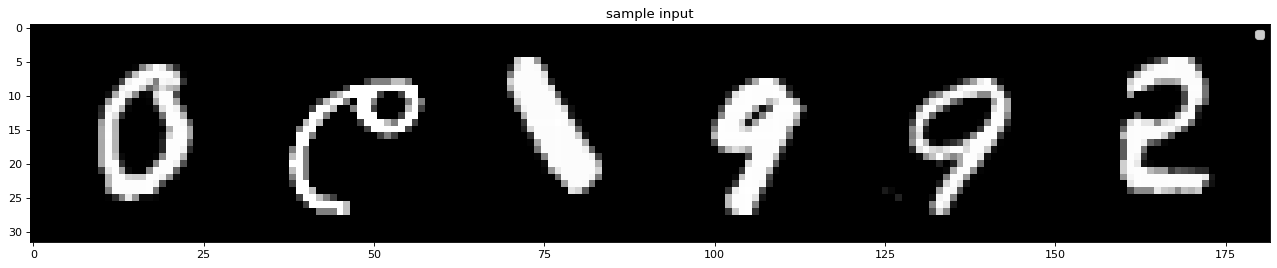

In [ ]:
# ToDo: plot the input images and output of your network for a few samples in the test set

fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,1)

test_iter = iter(test_loader)
network.eval()
for i in range(len(test_loader)):
    batch_cpu = next(test_iter)
    axes.cla()
    plot_images(batch_cpu['image'][0:6], ax=axes)
    axes.legend()
    axes.set_title('sample input')

    batch_gpu = dict_to_device(batch_cpu, 'cuda')
    pred = network(batch_gpu)

    # ToDo: code here. get the digits from the predicted probabilities.
    print("predicted digit:", None)
    print("predicted is_flipped:", None)

    break